*   Name : Molemi Molokoane
*   Email : iimillicent02@gmail.com

# Week 6 Assignment: Data Storytelling with Power BI

I answer the **Group B (Customer Experience and Deliveries)** questions. The dashboard itself is in **Power BI Desktop** (`power_bi/`, build steps in `Power_BI_Guide.md`). This notebook does two things:
1. Rebuilds `olist_reviews_master.csv` with the same joins as the class notebook.
2. Calculates the answer to each Group B question in pandas, so I can check that my Power BI visuals use the right aggregation (e.g. Average instead of the default Sum).

## 1. Load the Olist Data

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Local copy of the Olist dataset. In Colab, point this at the Drive folder instead.
DATA_DIR = "../Olist Dataset"
OUTPUT_DIR = "power_bi_datasets"
os.makedirs(OUTPUT_DIR, exist_ok=True)

orders = pd.read_csv(f"{DATA_DIR}/olist_orders_dataset.csv")
reviews = pd.read_csv(f"{DATA_DIR}/olist_order_reviews_dataset.csv")
customers = pd.read_csv(f"{DATA_DIR}/olist_customers_dataset.csv")

for name, df in [("orders", orders), ("reviews", reviews), ("customers", customers)]:
    print(f"{name:10s} {df.shape[0]:>7,} rows, {df.shape[1]} columns")

# Colours for the reference charts
BLUE, ORANGE = "#2a78d6", "#eb6834"

orders      99,441 rows, 8 columns
reviews     99,224 rows, 7 columns
customers   99,441 rows, 5 columns


## 2. Build the Reviews Master CSV
Same joins as the class notebook: one row per review, with its order dates and the customer's state.

In [2]:
reviews_master = (
    reviews
    .merge(orders, on="order_id", how="left")
    .merge(customers, on="customer_id", how="left")
)

# A left join must never add rows
assert len(reviews_master) == len(reviews)

reviews_master.to_csv(f"{OUTPUT_DIR}/olist_reviews_master.csv", index=False, encoding="utf-8")
print("reviews_master:", reviews_master.shape)

reviews_master: (99224, 18)


## 3. Check the Keys Before Modelling
The assignment suggests linking the reviews and sales tables on `order_id` as a **1-to-many** relationship. That only works if `order_id` is unique on one side.

In [3]:
print("Review rows per order_id (max): ", reviews_master["order_id"].value_counts().max())
print("Orders with more than one review:", reviews_master["order_id"].duplicated().sum())
print("Duplicated review_id values:     ", reviews_master["review_id"].duplicated().sum())

Review rows per order_id (max):  3


Orders with more than one review: 551
Duplicated review_id values:      814


`order_id` repeats in the reviews table, and it also repeats in the sales table (one row per item), so the link would be *many-to-many* and could double-count. All Group B questions only need the reviews table, so my Power BI model loads just this one table and needs no relationship.

## 4. Group B: Customer Experience and Deliveries

### B1. Which states have the lowest average review score?

                avg_score  reviews
customer_state                    
RR                   3.61       46
AL                   3.75      414
MA                   3.76      746
SE                   3.81      349
PA                   3.85      968
CE                   3.85     1329
BA                   3.86     3357
RJ                   3.87    12765
PI                   3.92      491
PE                   4.01     1646

Overall average: 4.09


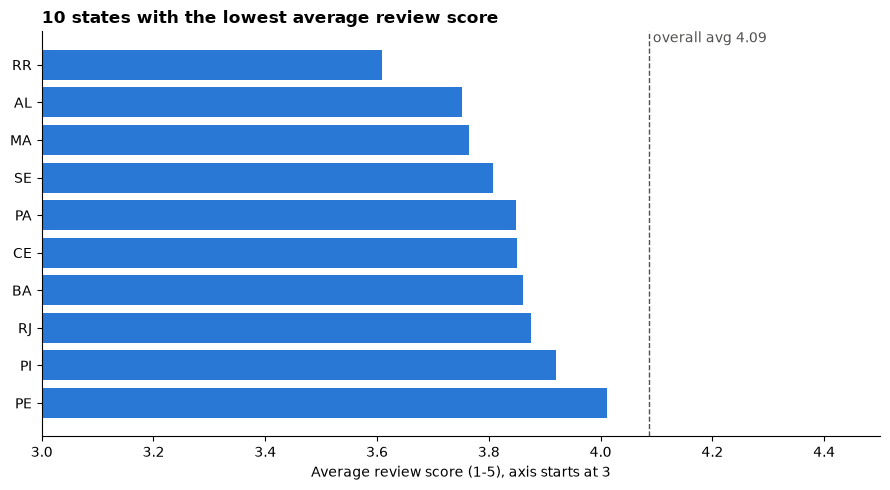

In [4]:
state_score = (reviews_master.groupby("customer_state")["review_score"]
               .agg(avg_score="mean", reviews="size")
               .sort_values("avg_score"))
overall = reviews_master["review_score"].mean()
print(state_score.round(2).head(10))
print(f"\nOverall average: {overall:.2f}")

lowest = state_score.head(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(lowest.index, lowest["avg_score"], color=BLUE)
ax.axvline(overall, color="#52514e", linestyle="--", linewidth=1)
ax.text(overall, 9.6, f" overall avg {overall:.2f}", color="#52514e")
ax.set_xlim(3, 4.5)
ax.set_title("10 states with the lowest average review score", loc="left", fontweight="bold")
ax.set_xlabel("Average review score (1-5), axis starts at 3")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Answer:** **Roraima (RR, 3.61)**, Alagoas (AL, 3.75), Maranhão (MA, 3.76), Sergipe (SE, 3.81) and Pará (PA, 3.85) have the lowest averages, all in the North and Northeast. RR has only 46 reviews, so its average is less reliable. Rio de Janeiro (3.87) is the only large market in the bottom ten; with 12,765 reviews it is the biggest problem area. These states are far from the São Paulo sellers, which points to delivery as a cause (checked in B3).

### B2. Distribution of review scores

              reviews  percent
review_score                  
1               11424     11.5
2                3151      3.2
3                8179      8.2
4               19142     19.3
5               57328     57.8


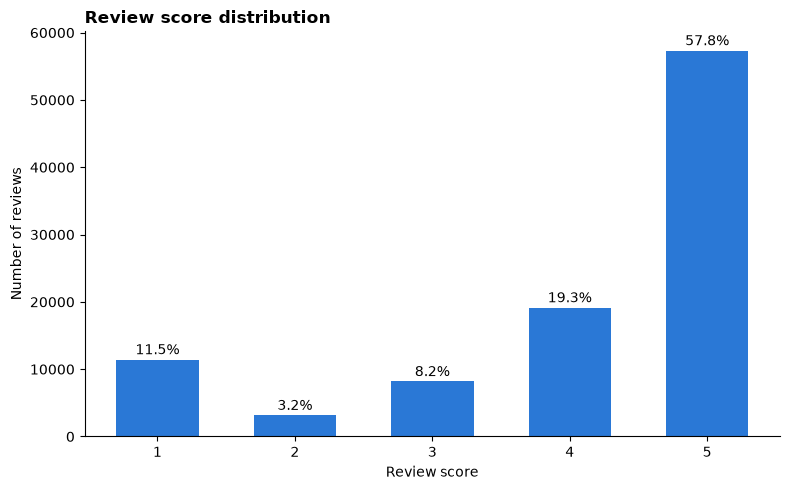

In [5]:
dist = reviews_master["review_score"].value_counts().sort_index()
pct = dist / dist.sum() * 100
print(pd.DataFrame({"reviews": dist, "percent": pct.round(1)}))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(dist.index, dist.values, color=BLUE, width=0.6)
for b, p in zip(bars, pct):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 800, f"{p:.1f}%", ha="center")
ax.set_title("Review score distribution", loc="left", fontweight="bold")
ax.set_xlabel("Review score")
ax.set_ylabel("Number of reviews")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Answer:** Most customers are happy: **57.8% give 5 stars** and 77% give 4 or 5. But the distribution is U-shaped: **11.5% give 1 star**, slightly more than the 2-star and 3-star reviews combined (11.4%). Unhappy customers tend to pick the lowest score rather than a middle one.

### B3. Is there a relationship between delivery delays and satisfaction?
**Delay (days)** = delivered date − estimated delivery date, in calendar days. Negative means it arrived early. Orders that were never delivered have no delay and are left out.

In [6]:
delivered = pd.to_datetime(reviews_master["order_delivered_customer_date"]).dt.normalize()
estimated = pd.to_datetime(reviews_master["order_estimated_delivery_date"]).dt.normalize()
reviews_master["delay_days"] = (delivered - estimated).dt.days

print("Reviews with no delivery date:", reviews_master["delay_days"].isna().sum())
has_delay = reviews_master.dropna(subset=["delay_days"]).copy()

has_delay["delivery_status"] = pd.cut(
    has_delay["delay_days"],
    bins=[-1000, -15, -8, -1, 0, 7, 14, 1000],
    labels=["15+ days early", "8-14 days early", "1-7 days early", "On time",
            "1-7 days late", "8-14 days late", "15+ days late"],
)
by_status = has_delay.groupby("delivery_status", observed=True)["review_score"].agg(
    avg_score="mean", reviews="size")
print(by_status.round(2))

late = has_delay["delay_days"] > 0
print(f"\nLate: {late.mean()*100:.1f}% of delivered orders, avg score {has_delay.loc[late, 'review_score'].mean():.2f}")
print(f"On time or early: avg score {has_delay.loc[~late, 'review_score'].mean():.2f}")
print(f"Correlation (delay vs score): {has_delay['delay_days'].corr(has_delay['review_score']):.2f}")

Reviews with no delivery date: 2865
                 avg_score  reviews
delivery_status                    
15+ days early        4.32    34983
8-14 days early       4.31    36356
1-7 days early        4.20    17319
On time               4.03     1291
1-7 days late         2.71     3612
8-14 days late        1.68     1453
15+ days late         1.72     1345

Late: 6.7% of delivered orders, avg score 2.27
On time or early: avg score 4.29
Correlation (delay vs score): -0.27


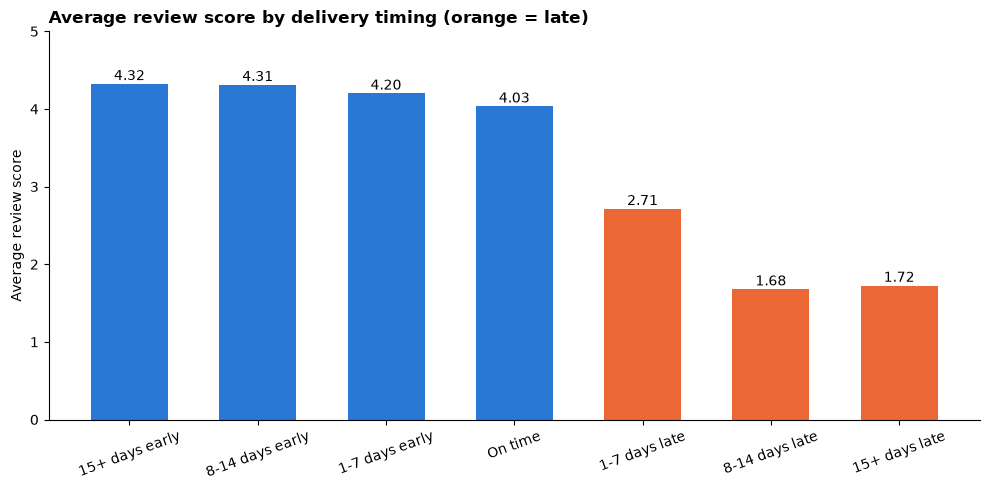

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
labels = by_status.index.astype(str)
bars = ax.bar(labels, by_status["avg_score"], width=0.6,
              color=[ORANGE if "late" in l else BLUE for l in labels])
for b, v in zip(bars, by_status["avg_score"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.05, f"{v:.2f}", ha="center")
ax.set_ylim(0, 5)
ax.set_title("Average review score by delivery timing (orange = late)", loc="left", fontweight="bold")
ax.set_ylabel("Average review score")
ax.tick_params(axis="x", rotation=20)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Answer:** Yes, and it is the strongest pattern in the Group B data. Orders that arrive early average **about 4.2–4.3 stars**. Once an order is late, satisfaction collapses: **2.71 stars at 1–7 days late, and about 1.7 at 8+ days late**.

The correlation is only about −0.27 because most orders arrive well before the estimate. The effect isn't a straight line; it's a sharp drop once the promised date is missed. Business lesson: keeping the delivery promise matters much more than delivering extra early.

## 5. Summary for the Dashboard
| Question | Key finding |
|---|---|
| B1 Lowest-rated states | RR, AL, MA, SE, PA (North/Northeast); RJ is the largest weak market |
| B2 Score distribution | 58% five-star, but 11.5% one-star (U-shape) |
| B3 Delay vs score | Late orders drop from ~4.2 to ~1.7–2.7 stars |